# Figure 1 — Make Panels

Generates abstract Figure 1 panels A–H (behaviour overview).
Based on: `notebooks/fig2_task_description_general_results.ipynb`

In [47]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import math
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy.stats import ttest_rel
from scipy.optimize import brentq
from matplotlib.ticker import FixedLocator

from adaptive_behavior import data_access, plotting
from adaptive_behavior.data_access import AddExtraColumns as Add
from adaptive_behavior.helpers import repo_root
from adaptive_behavior.style import apply_style, panel_fig, save_panel, PALETTE

color1, color2, color3 = "#d95f02", "#1b9e77", "#7570b3"
color_dict_label = {"90": color1, "60": color2, "0": color3}

S3_ROOT = "s3://aind-scratch-data/vr-foraging/vr-foraging-manuscript"
STORAGE_OPTIONS = {"skip_signature": "true"}
STAGES_CSV = "C:/git/aind-vr-foraging-paper/code/notebooks/results/sessions_stages.csv"

apply_style()
PANELS_DIR = repo_root() / "figures" / "fig1" / "panels"
PANELS_DIR.mkdir(parents=True, exist_ok=True)
print("Panels will be saved to:", PANELS_DIR)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Panels will be saved to: C:\git\cosyne2026_adaptive_behavior\figures\fig1\panels


In [48]:
EXCLUDED_SUBJECTS = {713578, 754575, 715866}

session_cat, valid_session_ids, macro_df = data_access.load_session_catalogue_and_sites(
    S3_ROOT, STORAGE_OPTIONS, EXCLUDED_SUBJECTS
)
macro_df = data_access.prepare_macro_df(
    macro_df,
    stage_filter=("data_collection", "control"),
    stages_csv=STAGES_CSV,
)
all_df = data_access.build_all_df(macro_df)
all_df = all_df[all_df["site_label"] == "RewardSite"].copy()
print(f"Loaded {all_df['mouse'].nunique()} mice, {all_df['session_id'].nunique()} sessions")


KeyboardInterrupt: 

## Panel B — Ethogram (raster with velocity)

Example session: behavior_754580_2024-10-15_09-20-17


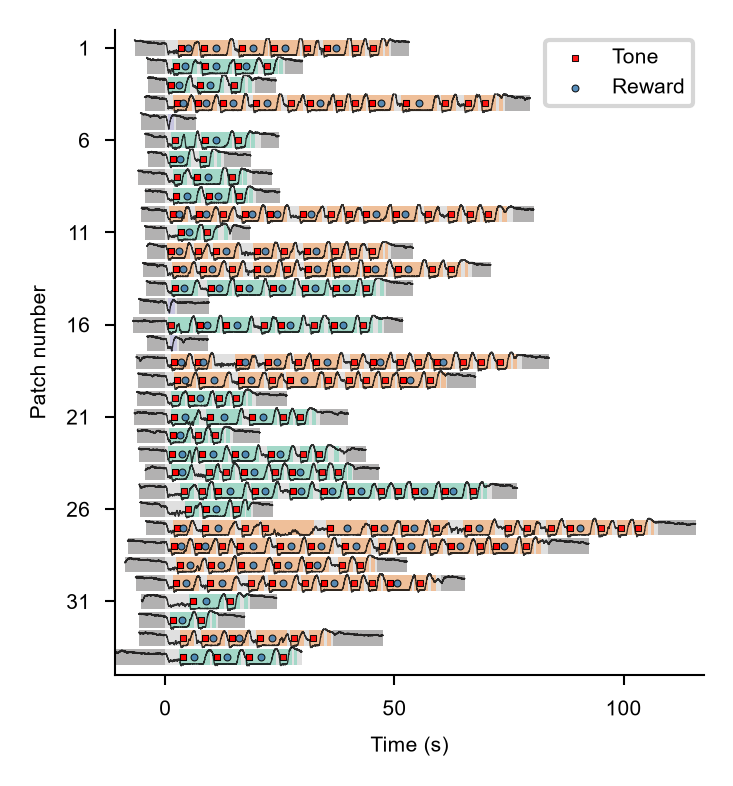

In [49]:
# --- Panel A: Ethogram (raster with velocity) ---
# Pick first available session from macro_df; override here if desired
example_session_id = "behavior_754580_2024-10-15_09-20-17"
print("Example session:", example_session_id)

# Load velocity
session_path = data_access.get_s3_location(example_session_id, S3_ROOT, STORAGE_OPTIONS)
pos_vel = (
    pl.read_parquet(
        f"{session_path}/position_velocity.parquet",
        storage_options=STORAGE_OPTIONS,
    )
    .to_pandas()
    .rename(columns={"Time": "times"})
)
vel_df = pos_vel[["times", "velocity"]].copy()

# Load all epoch types (InterSite, InterPatch, RewardSite) for this session
raw_epochs = (
    pl.scan_parquet(f"{S3_ROOT}/sites.parquet", storage_options=STORAGE_OPTIONS)
    .filter(pl.col("session_id") == example_session_id)
    .collect()
    .to_pandas()
)
# Add cumulative counters, patch onset, etc.
all_epochs = Add(raw_epochs).all_epochs
# Relabel patch tiers so color_dict_label keys match
all_epochs = data_access.prepare_macro_df(all_epochs, stages_csv=STAGES_CSV)

# Filter to a readable patch window (patch_index 6-40)
plot_df = all_epochs.loc[
    (all_epochs["patch_index"] >= 6) & (all_epochs["patch_index"] < 40)
].copy()
plot_df["patch_index"] = plot_df["patch_index"] - plot_df["patch_index"].min()

fig, ax = panel_fig("fig1_B")
apply_style()
plotting.raster_with_velocity(
    plot_df,
    vel_df,
    color_dict_label=color_dict_label,
    figsize=(fig, ax),
    bar_alpha=0.4,
)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Patch number")
sns.despine(ax=ax)
save_panel(fig, PANELS_DIR / "fig1_B.pdf")


## Panel C — P(stop) at first site

In [ ]:
# --- Panel B: P(stop) at first site by patch type ---
pre_df = (
    macro_df[
        (macro_df["site_label"] == "RewardSite")
        & (macro_df["site_index_in_patch_by_type"] == 0)
        & (macro_df["patch_index"] <= 40)
        & (macro_df["stage_name"].isin(["control", "data_collection"]))
    ]
    .groupby(["mouse", "session_id", "patch_label"])
    .agg({"has_choice": "mean"})
    .reset_index()
)
plot = pre_df.groupby(["mouse", "patch_label"])["has_choice"].mean().reset_index()

order = ["90", "60", "0"]
x_positions = {label: i for i, label in enumerate(order)}
colors_b = {"90": color1, "60": color2, "0": color3}

fig, ax = panel_fig("fig1_C")
for mouse, group in plot.groupby("mouse"):
    group = group.set_index("patch_label").reindex(order)
    xs = [x_positions[l] for l in order if l in group.index and not pd.isna(group.loc[l, "has_choice"])]
    ys = [group.loc[l, "has_choice"] for l in order if l in group.index and not pd.isna(group.loc[l, "has_choice"])]
    ax.plot(xs, ys, color="gray", alpha=0.4)

for label in order:
    subset = plot[plot["patch_label"] == label]["has_choice"]
    ax.errorbar(
        x_positions[label], subset.mean(), yerr=subset.std(),
        fmt="o", color=colors_b[label],
        capsize=0, capthick=0, elinewidth=0.5, markersize=2, zorder=3,
    )

ax.axhline(0, color="k", linestyle="--", linewidth=0.5)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["High", "Low", "Null"], rotation=45)
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-0.1, 1.05)
ax.set_yticks([0, 1])
ax.set_xlabel("")
ax.set_ylabel("P(stop) at \nfirst site")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig1_C.pdf")
# print("Saved fig1_C.pdf")


## Panel D

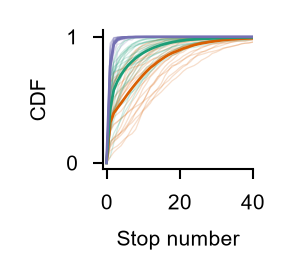

In [ ]:
# --- Panel D: CDF of stop number per patch ---
pre_df = all_df[all_df["patch_index"] <= 50].copy()
plot_raw = (
    pre_df.groupby(["mouse", "session_id", "patch_index", "patch_label"])
    ["site_index_in_patch_by_type"].max()
    .reset_index()
)
palette = {"0": color3, "60": color2, "90": color1}
x_vals = np.arange(-0.1, 40, 1)

records = []
for (mouse, label), grp in plot_raw.groupby(["mouse", "patch_label"]):
    cdf = np.mean(grp["site_index_in_patch_by_type"].values[:, None] <= x_vals, axis=0)
    for x, y in zip(x_vals, cdf):
        records.append({"mouse": mouse, "patch_label": label, "x": x, "cdf": y})
cdf_df = pd.DataFrame(records)

fig, ax = panel_fig("fig1_D")
for (mouse, label), grp in cdf_df.groupby(["mouse", "patch_label"]):
    ax.plot(grp["x"], grp["cdf"], color=palette[label], alpha=0.2, linewidth=0.3)

sns.lineplot(
    data=cdf_df, x="x", y="cdf",
    hue="patch_label", hue_order=["90", "60", "0"],
    palette=palette, ax=ax, errorbar=None, linewidth=0.65, legend=False,
)
ax.set_xlim(-1, 40)
ax.set_yticks(np.arange(0, 1.1,1))
ax.set_yticklabels(["0","1"])
ax.set_xlabel("Stop number")
ax.set_ylabel("CDF")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig1_D.pdf")

## Velocity panels C, E, G — shared data collection

This cell performs one S3 pass to collect velocity snippets for all three
velocity panels. Re-run only if the session list or filter criteria change.
Individual panel cells can be re-run independently after this.

In [54]:
# --- Shared velocity collection for panels C, E, G ---
# Runs one S3 pass over all sessions; re-run if data or filters change.
# Example session only (the one used in panel A) instead of every session
base = all_df[
    (all_df["session_id"] == example_session_id)
    & (all_df["patch_label"].isin(["60", "90", "0"]))
]

# Every stop (has_choice == 1), keeping the outcome (has_reward) so panels can split
# rewarded vs omission stops or average over them.
criteria = {
    "stops": base[(base["has_choice"] == 1)],
}
all_sessions = set().union(*(set(df["session_id"]) for df in criteria.values()))
results = {k: [] for k in criteria}

for session_id in sorted(all_sessions):
    try:
        session_path = data_access.get_s3_location(session_id, S3_ROOT, STORAGE_OPTIONS)
        vel = (
            pl.read_parquet(
                f"{session_path}/position_velocity.parquet",
                storage_options=STORAGE_OPTIONS,
            )
            .to_pandas()
            .rename(columns={"Time": "times"})[["times", "velocity"]]
        )
    except Exception as e:
        print(f"  velocity load failed for {session_id}: {e}")
        continue

    for key, base_df in criteria.items():
        df = base_df[base_df["session_id"] == session_id].copy()
        if df.empty:
            continue
        try:
            ts = plotting.trial_collection(df, vel, aligned="start_time", window=[-1, 4])
            ts = (
                ts.groupby(["times", "mouse", "patch_label", "session_id", "has_reward", "start_time"])  # one trace per stop
                .velocity.mean()
                .reset_index()
            )
            results[key].append(ts)
        except Exception as e:
            print(f"  {key} failed for {session_id}: {e}")

vel_dfs = {k: pd.concat(v, ignore_index=True) for k, v in results.items() if v}
for k, df in vel_dfs.items():
    df["times"] = df["times"].round(2)
    print(f"  {k}: {len(df)} rows, {df['mouse'].nunique()} mice")


  stops: 401250 rows, 1 mice


## Panel E — Velocity at first-site odor onset

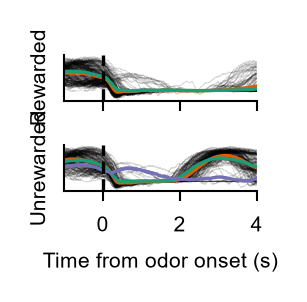

In [55]:
# --- Panel C: Velocity at first-site odor onset (rewarded on top, unrewarded below) ---
palette = {"90": color1, "60": color2, "0": color3}
key = "stops"
if key not in vel_dfs:
    raise RuntimeError("Run velocity collection cell first")

fig, axes = panel_fig("fig1_C", nrows=2, sharex=True)  # no sharey: the row names are y tick labels
y_lo, y_hi = vel_dfs[key]["velocity"].min() - 2, vel_dfs[key]["velocity"].max() + 2
rows = [(axes[0], True, "Rewarded"), (axes[1], False, "Unrewarded")]
for ax, rewarded, name in rows:
    d = vel_dfs[key][vel_dfs[key]["has_reward"].astype(bool) == rewarded]
    # every individual stop in black
    for _, trace in d.groupby("start_time"):
        ax.plot(trace["times"], trace["velocity"], color="black", alpha=0.15, linewidth=0.2, zorder=1)
    # mean per patch type
    means = d.groupby(["patch_label", "times"]).velocity.mean().reset_index()
    for label in ["90", "60", "0"]:
        m = means[means["patch_label"] == label]
        if not m.empty:
            ax.plot(m["times"], m["velocity"], color=palette[label], linewidth=0.8, zorder=2)
    ax.set_xlim(-1, 4)
    ax.set_ylim(y_lo, y_hi)  # same range in both rows
    ax.axvline(0, color="k", linestyle="--", linewidth=0.8, zorder=3)
    sns.despine(ax=ax)

# the left ticks name the row instead of giving values
for ax, rewarded, name in rows:
    ax.set_yticks([(y_lo + y_hi) / 2])
    ax.set_yticklabels([name], rotation=90, va="center")
    ax.tick_params(axis="y", length=0)
axes[1].set_xlabel("Time from odor onset (s)")
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig1_C.pdf")

## Panel G — Velocity at first-site stops (rewarded vs omission)

In [ ]:
# --- Panel G: Velocity at first-site stops, rewarded vs omission ---
palette = {"90": color1, "60": color2, "0": color3}
hue_order = ["90", "60", "0"]
reward_names = {"1": "Reward", "1.0": "Reward", "True": "Reward",
                "0": "Omission", "0.0": "Omission", "False": "Omission"}
key = "stops"
if key not in vel_dfs:
    raise RuntimeError("Run velocity collection cell first")

plot = (
    vel_dfs[key]
    .groupby(["mouse", "times", "patch_label", "has_reward"])
    .velocity.mean()
    .reset_index()
)
plot = plot[plot["patch_label"].isin(hue_order)]

fig, ax = panel_fig("fig1_G")
sns.lineplot(
    data=plot, x="times", y="velocity",
    hue="patch_label", hue_order=hue_order, palette=palette,
    style="has_reward", estimator="mean", errorbar="se",
    err_kws={"linewidth": 0}, legend=True, ax=ax,
)
ax.fill_between([-1, 4], -3, 8, color="gray", alpha=0.2, linewidth=0)
# keep only the has_reward (line style) legend entries, drop the patch hue entries
handles, labels = ax.get_legend_handles_labels()
if "has_reward" in labels:
    i = labels.index("has_reward")
    ax.legend(
        handles[i + 1:], [reward_names.get(l, l) for l in labels[i + 1:]],
        fontsize=5, frameon=False, handlelength=1,
    )
ax.vlines(0, -5, 60, color="k", linestyle="--", linewidth=0.8)
ax.set_ylim(-5, 50)
ax.set_yticks(range(0, 51, 25))
ax.set_xlim(-1, 4)
ax.set_xlabel("Time from odor onset (s)")
ax.set_ylabel("Velocity (cm/s)")
ax.text(0.25, 0.95, "Stop at first site", transform=ax.transAxes, fontsize=5, va="top")
sns.despine(ax=ax)
plt.tight_layout()
save_panel(fig, PANELS_DIR / "fig1_E.pdf")
print("Saved fig1_G.pdf")